Week 5 Notebook for Milestone 1

This week I predict frequent mental distress (14+ poor mental health days, about 14% of respondents) with support vector machines. I compare a linear SVM with two kernel SVMs (RBF and polynomial), which can draw curved boundaries between groups. I also tune the regularization strength (C) and kernel width (gamma) to control overfitting. As in Week 4, features are standardized and classes are weighted so the model can’t succeed by always predicting “no distress.” Logistic regression is included as a baseline.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

cols = ['MENTHLTH','PHYSHLTH','INCOME3','EMPLOY1','_HLTHPL2','MEDCOST1','GENHLTH','_AGE_G','_BMI5']
brfss = pd.read_sas('LLCP2024.XPT ', format='xport')[cols]

for c in ['MENTHLTH', 'PHYSHLTH']:
    brfss[c] = brfss[c].replace({88: 0, 77: np.nan, 99: np.nan})
brfss['INCOME3'] = brfss['INCOME3'].where(brfss['INCOME3'].between(1, 11))
brfss['GENHLTH'] = brfss['GENHLTH'].where(brfss['GENHLTH'].between(1, 5))
brfss['NO_INSURANCE'] = brfss['_HLTHPL2'].map({1: 0, 2: 1})
brfss['COST_BARRIER'] = brfss['MEDCOST1'].map({1: 1, 2: 0})
brfss['EMPLOY'] = brfss['EMPLOY1'].map({1: 'Employed', 2: 'SelfEmployed', 3: 'OutOfWork1yr+',
                                       4: 'OutOfWork<1yr', 5: 'Homemaker', 6: 'Student',
                                       7: 'Retired', 8: 'UnableToWork'})
brfss['BMI'] = brfss['_BMI5'] / 100
brfss = brfss.rename(columns={'_AGE_G': 'AGE_G'})

brfss = (brfss[['MENTHLTH','PHYSHLTH','INCOME3','GENHLTH','AGE_G','BMI',
                'NO_INSURANCE','COST_BARRIER','EMPLOY']]
         .dropna().sample(50_000, random_state=42).reset_index(drop=True))
brfss = pd.get_dummies(brfss, columns=['EMPLOY'], drop_first=True, dtype=int)

brfss['FMD'] = (brfss['MENTHLTH'] >= 14).astype(int)
X, y = brfss.drop(columns=['MENTHLTH', 'FMD']), brfss['FMD']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_tr)
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=X.columns)
X_te_s = pd.DataFrame(scaler.transform(X_te), columns=X.columns)
y_tr = y_tr.reset_index(drop=True)

X_tune, _, y_tune, _ = train_test_split(X_tr_s, y_tr, train_size=8000, stratify=y_tr, random_state=42)
X_fit,  _, y_fit,  _ = train_test_split(X_tr_s, y_tr, train_size=15000, stratify=y_tr, random_state=42)
print('FMD rate:', round(y.mean(), 3), '| tuning rows:', len(X_tune), '| final-fit rows:', len(X_fit))

FMD rate: 0.141 | tuning rows: 8000 | final-fit rows: 15000


14.1% of respondents are in frequent mental distress. Kernel SVMs slow down sharply as rows increase, so models are tuned on an 8,000-row subsample, trained on 15,000 rows, and scored on the full 10,000-row test set.

In [3]:
cv = StratifiedKFold(3, shuffle=True, random_state=42)
grid = [
    {'kernel': ['linear'], 'C': [0.01, 0.1, 1]},
    {'kernel': ['rbf'],    'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1]},
    {'kernel': ['poly'],   'C': [0.1, 1], 'degree': [2, 3]},
]
gs = GridSearchCV(SVC(class_weight='balanced'), grid, cv=cv, scoring='roc_auc',
                  return_train_score=True, n_jobs=-1)
gs.fit(X_tune, y_tune)

res = pd.DataFrame(gs.cv_results_)
show = res[['param_kernel', 'params', 'mean_train_score', 'mean_test_score']].copy()
show['params'] = show['params'].astype(str)
show = show.rename(columns={'mean_train_score': 'train_AUC', 'mean_test_score': 'cv_AUC'})
print(show.sort_values('cv_AUC', ascending=False).round(4).to_string(index=False))

best_params = {}
for k in ['linear', 'rbf', 'poly']:
    sub = res[res['param_kernel'] == k]
    best_params[k] = sub.loc[sub['mean_test_score'].idxmax(), 'params']
print('\nBest per kernel:', best_params)

param_kernel                                        params  train_AUC  cv_AUC
      linear               {'C': 0.01, 'kernel': 'linear'}     0.8030  0.7979
      linear                {'C': 0.1, 'kernel': 'linear'}     0.8030  0.7976
      linear                  {'C': 1, 'kernel': 'linear'}     0.8030  0.7975
         rbf      {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}     0.8072  0.7974
         rbf    {'C': 0.1, 'gamma': 0.01, 'kernel': 'rbf'}     0.8016  0.7966
         rbf     {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}     0.8143  0.7914
         rbf {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}     0.8007  0.7838
         rbf   {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}     0.8229  0.7824
         rbf     {'C': 0.1, 'gamma': 0.1, 'kernel': 'rbf'}     0.8034  0.7806
        poly     {'C': 0.1, 'degree': 3, 'kernel': 'poly'}     0.8080  0.7804
         rbf       {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}     0.8312  0.7784
         rbf  {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}     0

The linear SVM scored best in cross-validation (AUC 0.798), and its result barely changed across C values. The best RBF model (C = 1, gamma = 0.01) tied it at 0.797. A small gamma makes the RBF boundary smooth and nearly linear, so the extra flexibility of the kernel trick added nothing. The polynomial kernels did worst (0.747–0.780). The most flexible settings show clear overfitting: RBF with C = 10 and gamma = 0.1 reached 0.870 AUC on training data but only 0.746 in cross-validation.

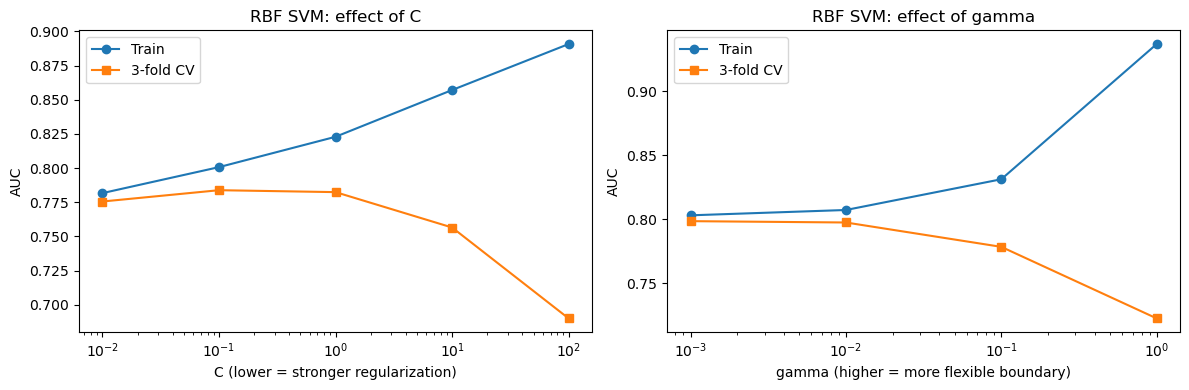

     C  train_AUC  cv_AUC
  0.01     0.7817  0.7755
  0.10     0.8007  0.7838
  1.00     0.8229  0.7824
 10.00     0.8571  0.7565
100.00     0.8907  0.6900
 gamma  train_AUC  cv_AUC
 0.001     0.8030  0.7984
 0.010     0.8072  0.7974
 0.100     0.8312  0.7784
 1.000     0.9369  0.7224


In [4]:
Cs, gammas = np.logspace(-2, 2, 5), [0.001, 0.01, 0.1, 1]
tr_C, cv_C = validation_curve(SVC(kernel='rbf', gamma='scale', class_weight='balanced'), X_tune, y_tune,
                              param_name='C', param_range=Cs, cv=cv, scoring='roc_auc', n_jobs=-1)
tr_g, cv_g = validation_curve(SVC(kernel='rbf', C=1, class_weight='balanced'), X_tune, y_tune,
                              param_name='gamma', param_range=gammas, cv=cv, scoring='roc_auc', n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, rng, tr, cvs, name in [(ax[0], Cs, tr_C, cv_C, 'C (lower = stronger regularization)'),
                              (ax[1], gammas, tr_g, cv_g, 'gamma (higher = more flexible boundary)')]:
    a.semilogx(rng, tr.mean(1), 'o-', label='Train')
    a.semilogx(rng, cvs.mean(1), 's-', label='3-fold CV')
    a.set_xlabel(name); a.set_ylabel('AUC'); a.legend()
ax[0].set_title('RBF SVM: effect of C'); ax[1].set_title('RBF SVM: effect of gamma')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'C': Cs, 'train_AUC': tr_C.mean(1), 'cv_AUC': cv_C.mean(1)}).round(4).to_string(index=False))
print(pd.DataFrame({'gamma': gammas, 'train_AUC': tr_g.mean(1), 'cv_AUC': cv_g.mean(1)}).round(4).to_string(index=False))

These curves show regularization at work. As C increases (weaker regularization), training AUC climbs from 0.78 to 0.89, but cross-validated AUC peaks at C = 0.1 (0.784) and falls to 0.69 at C = 100, where the model memorizes noise. Gamma behaves the same way: at gamma = 1 the boundary bends around individual points, so training AUC hits 0.94 while CV AUC drops to 0.72. The best results come from small gamma and moderate C, meaning a simple, smooth boundary.

In [5]:
models = {
    'SVM linear':  SVC(**best_params['linear'], class_weight='balanced'),
    'SVM RBF':     SVC(**best_params['rbf'],    class_weight='balanced'),
    'SVM poly':    SVC(**best_params['poly'],   class_weight='balanced'),
    'Logistic regression (baseline)': LogisticRegression(class_weight='balanced', max_iter=1000),
}
rows = []
for name, m in models.items():
    m.fit(X_fit, y_fit)
    score, pred = m.decision_function(X_te_s), m.predict(X_te_s)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_te, pred),
                 'recall':   recall_score(y_te, pred),
                 'AUC':      roc_auc_score(y_te, score),
                 'support_vectors': int(m.n_support_.sum()) if hasattr(m, 'n_support_') else None})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                         model  accuracy  recall   AUC  support_vectors
                    SVM linear     0.754   0.630 0.777           9684.0
                       SVM RBF     0.730   0.670 0.773           9403.0
                      SVM poly     0.774   0.539 0.755           9833.0
Logistic regression (baseline)     0.733   0.663 0.776              NaN


On the test set, the linear SVM (AUC 0.777), RBF SVM (0.773) and logistic regression (0.776) perform almost identically. The polynomial SVM looks more accurate (77%), but only because it predicts “no distress” more often, so it catches just 54% of distressed respondents. That makes it the worst choice for flagging people at risk. Each SVM uses about 9,400–9,800 support vectors, roughly two-thirds of the 15,000 training rows. When that many points sit on or inside the margin, the two groups overlap heavily on these features. The conclusion: the relationship between these factors and distress is essentially linear, and logistic regression does just as well while being faster and easier to interpret.